# eFL-Boost: Efficient Federated Learning for GBDT (Yamamoto, Ozawa & Wang, IEEE Access 2022)

# Imports

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
from dataclasses import dataclass, field
from typing import Dict, List, Tuple, Optional, Any
from collections import defaultdict, Counter
import time
import sys
import pickle
import os
import json
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import LabelEncoder
import copy
import io
import contextlib

# Utility funcs (from FedTree.ipynb)

In [2]:
def sizeof_mb(obj: Any) -> float:
    return sys.getsizeof(pickle.dumps(obj, protocol=pickle.HIGHEST_PROTOCOL)) / (1024 * 1024)

def measure_inference_time(predict_fn, X, n_runs: int = 5) -> dict:
    times = []
    for _ in range(n_runs):
        t0 = time.perf_counter()
        _ = predict_fn(X)
        times.append(time.perf_counter() - t0)
    total = float(np.median(times))
    per_sample = total / max(len(X), 1) * 1000
    return {
        "test_time_total_s": total,
        "test_time_per_sample_ms": per_sample,
    }


def softmax(scores: np.ndarray) -> np.ndarray:
    scores = scores - scores.max(axis=1, keepdims=True)
    exp = np.exp(scores)
    return exp / exp.sum(axis=1, keepdims=True)

# Cut points

In [3]:
@dataclass
class CutPoints:
    boundaries: Dict[int, np.ndarray]

    @staticmethod
    def compute(X: np.ndarray, n_bins: int = 32) -> "CutPoints":
        boundaries = {}
        quantiles = np.linspace(0, 1, n_bins + 1)[1:-1]
        for f in range(X.shape[1]):
            col = X[:, f]
            cuts = np.unique(np.quantile(col, quantiles))
            if len(cuts) == 0:
                cuts = np.array([np.median(col)])
            boundaries[f] = cuts
        return CutPoints(boundaries=boundaries)

# Histogram helpers

In [4]:
def compute_local_histogram(
    X: np.ndarray, g: np.ndarray, h: np.ndarray,
    instance_ids: np.ndarray, cuts: CutPoints
) -> Dict[int, np.ndarray]:
    hist = {}
    if len(instance_ids) == 0:
        for f, bnds in cuts.boundaries.items():
            hist[f] = np.zeros((len(bnds) + 1, 2), dtype=np.float64)
        return hist

    Xn = X[instance_ids]
    gn = g[instance_ids]
    hn = h[instance_ids]

    for f, bnds in cuts.boundaries.items():
        bin_idx = np.searchsorted(bnds, Xn[:, f], side="left")
        n_bins = len(bnds) + 1
        gh = np.zeros((n_bins, 2), dtype=np.float64)
        np.add.at(gh[:, 0], bin_idx, gn)
        np.add.at(gh[:, 1], bin_idx, hn)
        hist[f] = gh
    return hist


def aggregate_histograms(client_hists: List[Dict[int, np.ndarray]]) -> Dict[int, np.ndarray]:
    agg = {f: np.zeros_like(h) for f, h in client_hists[0].items()}
    for hist in client_hists:
        for f, gh in hist.items():
            agg[f] += gh
    return agg

# Split gain & leaf value (from FedTree.ipynb)

In [5]:
def leaf_value(G: float, H: float, lam: float) -> float:
    return -G / (H + lam)


def split_gain(GL, HL, GR, HR, lam, gamma) -> float:
    def term(G, H):
        return (G * G) / (H + lam) if (H + lam) > 1e-12 else 0.0
    return 0.5 * (term(GL, HL) + term(GR, HR) - term(GL + GR, HL + HR)) - gamma


def find_best_split(agg_hist: Dict[int, np.ndarray], cuts: CutPoints,
                    lam: float, gamma: float, min_child_weight: float = 1.0
                    ) -> Optional[Tuple[int, float, float]]:
    best_gain, best_feat, best_cut = -np.inf, None, None

    for f, gh in agg_hist.items():
        bnds = cuts.boundaries[f]
        cum_g = np.cumsum(gh[:, 0])
        cum_h = np.cumsum(gh[:, 1])
        G_tot, H_tot = cum_g[-1], cum_h[-1]

        for i in range(len(bnds)):
            GL, HL = cum_g[i], cum_h[i]
            GR, HR = G_tot - GL, H_tot - HL
            if HL < min_child_weight or HR < min_child_weight:
                continue
            gain = split_gain(GL, HL, GR, HR, lam, gamma)
            if gain > best_gain:
                best_gain = gain
                best_feat = f
                best_cut = bnds[i]

    if best_feat is None or best_gain <= 0:
        return None
    return best_feat, best_cut, best_gain

# Tree node & prediction (from FedTree.ipynb)

In [6]:
@dataclass
class TreeNode:
    is_leaf: bool = False
    feature: Optional[int] = None
    threshold: Optional[float] = None
    value: float = 0.0
    left: Optional["TreeNode"] = None
    right: Optional["TreeNode"] = None


def predict_tree(node: TreeNode, X: np.ndarray) -> np.ndarray:
    out = np.zeros(X.shape[0])
    def _rec(n, idx):
        if n.is_leaf or len(idx) == 0:
            out[idx] = n.value
            return
        go_left = X[idx, n.feature] <= n.threshold
        _rec(n.left, idx[go_left])
        _rec(n.right, idx[~go_left])
    _rec(node, np.arange(X.shape[0]))
    return out

# Tree building (from FedTree.ipynb)

In [7]:
def build_one_federated_tree(
    client_X: Dict[int, np.ndarray],
    client_g: Dict[int, np.ndarray],
    client_h: Dict[int, np.ndarray],
    cuts: CutPoints,
    max_depth: int,
    lam: float,
    gamma: float,
    learning_rate: float,
    min_child_weight: float,
    comm_tracker: Dict[str, float],
) -> TreeNode:

    client_ids = list(client_X.keys())
    client_inst = {cid: np.arange(client_X[cid].shape[0]) for cid in client_ids}

    root = TreeNode()
    frontier = [(root, client_inst, 0)]

    while frontier:
        node, inst_map, depth = frontier.pop(0)

        client_hists = []
        for cid in client_ids:
            hist = compute_local_histogram(
                client_X[cid], client_g[cid], client_h[cid],
                inst_map[cid], cuts
            )
            client_hists.append(hist)
            comm_tracker["upload_mb"] += sizeof_mb(hist)

        agg = aggregate_histograms(client_hists)

        any_f = next(iter(agg))
        G_total = agg[any_f][:, 0].sum()
        H_total = agg[any_f][:, 1].sum()

        can_split = depth < max_depth
        split = find_best_split(agg, cuts, lam, gamma, min_child_weight) if can_split else None

        if split is None:
            node.is_leaf = True
            node.value = leaf_value(G_total, H_total, lam) * learning_rate
            continue

        feat, thresh, _ = split
        node.feature = feat
        node.threshold = thresh
        node.left = TreeNode()
        node.right = TreeNode()
        comm_tracker["download_mb"] += sizeof_mb((feat, thresh))

        next_left, next_right = {}, {}
        for cid in client_ids:
            ids = inst_map[cid]
            if len(ids) == 0:
                next_left[cid] = ids
                next_right[cid] = ids
                continue
            vals = client_X[cid][ids, feat]
            mask = vals <= thresh
            next_left[cid] = ids[mask]
            next_right[cid] = ids[~mask]

        frontier.append((node.left, next_left, depth + 1))
        frontier.append((node.right, next_right, depth + 1))

    return root

# Partitioning (from FedTree.ipynb)

In [8]:
def partition_iid(X: np.ndarray, y: np.ndarray, n_clients: int, seed: int = 42):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    splits = np.array_split(idx, n_clients)
    return {i: (X[s], y[s]) for i, s in enumerate(splits)}


def partition_dirichlet(X: np.ndarray, y: np.ndarray, n_clients: int,
                        alpha: float = 0.5, seed: int = 42):
    rng = np.random.default_rng(seed)
    labels = np.unique(y)
    client_idx = defaultdict(list)

    for c in labels:
        idx_c = np.where(y == c)[0]
        rng.shuffle(idx_c)
        proportions = rng.dirichlet([alpha] * n_clients)
        proportions = (np.cumsum(proportions) * len(idx_c)).astype(int)[:-1]
        splits = np.split(idx_c, proportions)
        for i, s in enumerate(splits):
            client_idx[i].extend(s)

    return {i: (X[idxs], y[idxs]) for i, idxs in client_idx.items()}

# eFL-Boost helpers

In [9]:
def collect_leaves(node: TreeNode) -> List[TreeNode]:
    if node.is_leaf:
        return [node]
    return collect_leaves(node.left) + collect_leaves(node.right)


def count_nodes(node: TreeNode) -> int:
    return 1 if node.is_leaf else 1 + count_nodes(node.left) + count_nodes(node.right)


def structure_only(node: TreeNode) -> TreeNode:
    tree = copy.deepcopy(node)
    for leaf in collect_leaves(tree):
        leaf.value = 0.0
    return tree


def route_to_leaves(node: TreeNode, X: np.ndarray) -> np.ndarray:
    out = np.zeros(X.shape[0], dtype=np.int64)
    counter = [0]
    def _rec(n, idx):
        if n.is_leaf:
            out[idx] = counter[0]
            counter[0] += 1
            return
        go_left = X[idx, n.feature] <= n.threshold
        _rec(n.left, idx[go_left])
        _rec(n.right, idx[~go_left])
    _rec(node, np.arange(X.shape[0]))
    return out


def choose_builder(t: int, client_ids: List[int], sizes: Dict[int, int], rule: str,
                   rng: np.random.Generator, min_samples: int) -> int:
    eligible = [c for c in client_ids if sizes[c] >= min_samples]
    if rule == "round_robin":
        return eligible[t % len(eligible)]
    if rule == "random":
        return int(rng.choice(eligible))
    raise ValueError(rule)

# eFL-Boost

In [10]:
@dataclass
class EFLBoostConfig:
    n_trees: int = 50
    max_depth: int = 6
    n_bins: int = 64
    learning_rate: float = 0.1
    lam: float = 0.1
    gamma: float = 0.001
    min_child_weight: float = 0
    random_state: int = 42
    builder_rule: str = "round_robin"
    min_builder_samples: int = 2


class EFLBoost:
    def __init__(self, cfg: EFLBoostConfig):
        self.cfg = cfg
        self.trees: List[List[TreeNode]] = []
        self.classes_: np.ndarray = None
        self.builders: List[int] = []
        self.comm_rounds = 0
        self.comm_mb = {"structure_mb": 0.0, "leaf_stats_mb": 0.0, "leaf_values_mb": 0.0}
        self.n_messages = 0

    def _send(self, payload, kind: str, n_receivers: int = 1):
        self.comm_mb[kind] += sizeof_mb(payload) * n_receivers
        self.n_messages += n_receivers
        return payload

    def fit(self, client_data: Dict[int, Tuple[np.ndarray, np.ndarray]]):
        cfg = self.cfg
        rng = np.random.default_rng(cfg.random_state)
        client_ids = sorted(client_data.keys())
        client_X = {cid: client_data[cid][0] for cid in client_ids}
        client_y = {cid: client_data[cid][1] for cid in client_ids}
        sizes = {cid: len(client_y[cid]) for cid in client_ids}
        M = len(client_ids)

        self.classes_ = np.unique(np.concatenate([client_y[c] for c in client_ids]))
        K = len(self.classes_)
        class_to_idx = {c: i for i, c in enumerate(self.classes_)}
        client_yi = {cid: np.array([class_to_idx[v] for v in client_y[cid]], dtype=np.int64) for cid in client_ids}
        client_score = {cid: np.zeros((sizes[cid], K)) for cid in client_ids}
        local_cuts = {}

        for t in range(cfg.n_trees):
            client_g, client_h = {}, {}
            for cid in client_ids:
                p = softmax(client_score[cid])
                g = p.copy()
                g[np.arange(sizes[cid]), client_yi[cid]] -= 1.0
                client_g[cid], client_h[cid] = g, p * (1.0 - p)

            b = choose_builder(t, client_ids, sizes, cfg.builder_rule, rng, cfg.min_builder_samples)
            self.builders.append(b)
            if b not in local_cuts:
                local_cuts[b] = CutPoints.compute(client_X[b], n_bins=cfg.n_bins)
            structures = []
            for k in range(K):
                local_tree = build_one_federated_tree(
                    {b: client_X[b]}, {b: client_g[b][:, k]}, {b: client_h[b][:, k]}, local_cuts[b],
                    max_depth=cfg.max_depth, lam=cfg.lam, gamma=cfg.gamma, learning_rate=cfg.learning_rate,
                    min_child_weight=cfg.min_child_weight,
                    comm_tracker={"upload_mb": 0.0, "download_mb": 0.0},
                )
                structures.append(structure_only(local_tree))

            self.comm_rounds += 1
            self._send(structures, "structure_mb", n_receivers=M - 1)

            self.comm_rounds += 1
            n_leaves = [len(collect_leaves(s)) for s in structures]
            total = [np.zeros((n_leaves[k], 2)) for k in range(K)]
            client_leaf_idx = {}
            for cid in client_ids:
                stats, idx_k = [], []
                for k in range(K):
                    leaf_idx = route_to_leaves(structures[k], client_X[cid])
                    idx_k.append(leaf_idx)
                    G = np.bincount(leaf_idx, weights=client_g[cid][:, k], minlength=n_leaves[k])
                    H = np.bincount(leaf_idx, weights=client_h[cid][:, k], minlength=n_leaves[k])
                    stats.append(np.stack([G, H], axis=1))
                client_leaf_idx[cid] = idx_k
                for k, s in enumerate(self._send(stats, "leaf_stats_mb")):
                    total[k] += s

            leaf_values = [np.array([leaf_value(G, H, cfg.lam) * cfg.learning_rate for G, H in total[k]])
                           for k in range(K)]

            self.comm_rounds += 1
            self._send(leaf_values, "leaf_values_mb", n_receivers=M)
            round_trees = []
            for k in range(K):
                tree = copy.deepcopy(structures[k])
                for leaf, v in zip(collect_leaves(tree), leaf_values[k]):
                    leaf.value = float(v)
                round_trees.append(tree)
                for cid in client_ids:
                    client_score[cid][:, k] += leaf_values[k][client_leaf_idx[cid][k]]
            self.trees.append(round_trees)

            if (t + 1) % 10 == 0:
                print(f"  Boosting round {t + 1}/{cfg.n_trees} done (builder = client {b})")
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        scores = np.zeros((X.shape[0], len(self.classes_)))
        for round_trees in self.trees:
            for k, tree in enumerate(round_trees):
                scores[:, k] += predict_tree(tree, X)
        return self.classes_[np.argmax(scores, axis=1)]

    def score(self, X: np.ndarray, y: np.ndarray) -> Dict[str, float]:
        y_pred = self.predict(X)
        return {
            "accuracy": accuracy_score(y, y_pred) * 100,
            "f1_macro": f1_score(y, y_pred, average="macro", zero_division=0) * 100,
            "f1_weighted": f1_score(y, y_pred, average="weighted", zero_division=0) * 100,
        }

# Full pipeline

In [11]:
ALL_RESULTS = []


def run_eflboost(
    df: pd.DataFrame,
    dataset_name: str,
    label_col: str = "Label",
    partition_mode: str = "iid",
    n_clients: int = 10,
    dirichlet_alpha: float = 0.5,
    n_trees: int = 50,
    max_depth: int = 6,
    n_bins: int = 64,
    learning_rate: float = 0.1,
    lam: float = 0.1,
    builder_rule: str = "round_robin",
    tuned: Any = False,
    test_size: float = 0.20,
    random_state: int = 42,
    verbose: bool = True,
    rerun: bool = False,
) -> Dict:
    alpha = dirichlet_alpha if partition_mode == "dirichlet" else None
    params = dict(n_boosting_rounds=n_trees, max_depth=max_depth, learning_rate=learning_rate, n_bins=n_bins, lam=lam)
    done = [r for r in ALL_RESULTS if r["dataset"] == dataset_name and r["partition"] == partition_mode
            and r["alpha"] == alpha and r["tuned"] == tuned and r["n_clients"] == n_clients
            and all(np.isclose(r[k], v) for k, v in params.items())]
    if done and not rerun:
        print(f"{dataset_name} | {partition_mode} | tuned={tuned}: already in the checkpoint, skipped")
        return {"row": done[-1]}

    feature_cols = [c for c in df.columns if c != label_col]
    X = df[feature_cols].values.astype(np.float64)
    y = df[label_col].values

    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    if partition_mode == "iid":
        client_data = partition_iid(X_tr, y_tr, n_clients, seed=random_state)
    else:
        client_data = partition_dirichlet(X_tr, y_tr, n_clients, alpha=dirichlet_alpha, seed=random_state)

    if verbose:
        print(f"Dataset: {dataset_name} {df.shape} | mode={partition_mode} | clients={n_clients}")
        print(f"Params : n_trees={n_trees}, max_depth={max_depth}, learning_rate={learning_rate}, n_bins={n_bins}, "
              f"lam={lam}, tuned={tuned}")
        for cid, (Xc, yc) in client_data.items():
            print(f"  Client {cid}: {len(yc)} samples, classes={dict(Counter(yc))}")

    cfg = EFLBoostConfig(n_trees=n_trees, max_depth=max_depth, n_bins=n_bins, learning_rate=learning_rate,
                         lam=lam, random_state=random_state, builder_rule=builder_rule)

    t0 = time.perf_counter()
    model = EFLBoost(cfg)
    model.fit(client_data)
    train_time = time.perf_counter() - t0

    metrics = model.score(X_te, y_te)
    inf_stats = measure_inference_time(model.predict, X_te)
    model_size_mb = sizeof_mb(model.trees)
    refs = UTILITY_REFS.get((dataset_name, partition_mode))
    metrics["utility"] = (float(utility(metrics["f1_macro"], inf_stats["test_time_per_sample_ms"], model_size_mb, refs))
                          if refs else np.nan)
    search = search_info(dataset_name, partition_mode, tuned,
                         dict(n_trees=n_trees, max_depth=max_depth, learning_rate=learning_rate, n_bins=n_bins, lam=lam))
    n_tree_objs = sum(len(r) for r in model.trees)
    n_nodes = sum(count_nodes(t) for r in model.trees for t in r)
    total_comm_mb = sum(model.comm_mb.values())
    y_pred = model.predict(X_te)

    results = {
        "metrics": metrics,
        "efficiency": {
            "n_clients": n_clients,
            "n_boosting_rounds": n_trees,
            "max_depth": max_depth,
            "train_time_s": train_time,
            "test_time_total_s": inf_stats["test_time_total_s"],
            "test_time_per_sample_ms": inf_stats["test_time_per_sample_ms"],
            "model_size_mb": model_size_mb,
            "n_trees": n_tree_objs,
            "n_nodes": n_nodes,
            "n_comm_rounds": model.comm_rounds,
            "n_messages": model.n_messages,
            **model.comm_mb,
            "total_comm_mb": total_comm_mb,
        },
        "search": search,
        "builders": model.builders,
        "model": model,
        "y_test": y_te,
        "y_pred": y_pred,
        "classification_report": classification_report(y_te, y_pred, zero_division=0, output_dict=True),
    }
    ALL_RESULTS.append({"dataset": dataset_name, "partition": partition_mode, "alpha": alpha,
                        "tuned": tuned, "learning_rate": learning_rate, "n_bins": n_bins, "lam": lam,
                        **metrics, **results["efficiency"], **search})
    save_checkpoint()

    if verbose:
        e = results["efficiency"]
        print("\n===== RESULTS =====")
        print(f"Accuracy     : {metrics['accuracy']:.2f}%")
        print(f"F1-macro     : {metrics['f1_macro']:.2f}%")
        print(f"F1-weighted  : {metrics['f1_weighted']:.2f}%")
        print(f"Utility      : {metrics['utility']:.4f}" if refs else "Utility      : (after the first search)")
        if search:
            print(f"Search       : {search['algorithm']}, {search['max_trials']} trials max, 99 % of the front after "
                  f"{search['trials_to_99pct_hv']}, {search['search_time_min']:.1f} min | validation F1-macro "
                  f"{search['val_f1_macro']:.2f}%, utility {search['val_utility']:.4f}")
        print("\n===== EFFICIENCY =====")
        print(f"Train time          : {train_time:.1f} s")
        print(f"Test time (total)   : {e['test_time_total_s']:.4f} s")
        print(f"Test time / sample  : {e['test_time_per_sample_ms']:.4f} ms")
        print(f"Model size          : {model_size_mb:.3f} MB | {n_tree_objs} trees | {n_nodes} nodes")
        print(f"Total communication : {total_comm_mb:.2f} MB  (structures {e['structure_mb']:.2f} | "
              f"leaf stats {e['leaf_stats_mb']:.2f} | leaf values {e['leaf_values_mb']:.2f})")
        print(f"Comm rounds         : {model.comm_rounds}  ({model.n_messages} messages)")
        print(f"Builders per round  : {dict(sorted(Counter(model.builders).items()))}")
        print("\nClassification Report:")
        print(classification_report(y_te, y_pred, zero_division=0))

    return results

# Multi-objective optimisation (maximise macro-F1, minimise testing time)

In [12]:
try:
    import optuna
except ImportError:
    %pip install -q optuna
    import optuna
import matplotlib.pyplot as plt

MOO_SPACE = {
    "n_trees": (10, 100, 10),
    "max_depth": (2, 8),
    "learning_rate": (0.05, 0.5),
    "n_bins": [32, 64, 128],
    "lam": (0.01, 10.0),
}
MOO_FRONTS = {}
MOO_ALGORITHMS = {"nsga2": "NSGA-II", "nsga3": "NSGA-III", "random": "random search"}
UTILITY_WEIGHTS = {"f1": 0.7, "time": 0.2, "size": 0.1}
UTILITY_REFS = {}
VAL_COLS = ["val_accuracy", "val_f1_macro", "val_f1_weighted", "val_utility", "val_time_total_s",
            "val_time_per_sample_ms", "val_model_size_mb", "val_n_nodes"]


def utility(f1_macro, time_ms, size_mb, refs: Dict[str, float], weights: Optional[Dict[str, float]] = None):
    w = weights or UTILITY_WEIGHTS
    f = np.asarray(f1_macro, dtype=float) / 100
    t = 1 - np.clip(np.asarray(time_ms, dtype=float) / refs["time_ms"], 0, 1)
    s = 1 - np.clip(np.asarray(size_mb, dtype=float) / refs["size_mb"], 0, 1)
    return (w["f1"] * f + w["time"] * t + w["size"] * s) / sum(w.values())


def search_algorithm(tuned) -> Optional[str]:
    if not isinstance(tuned, str) or not tuned.startswith("moo"):
        return None
    return "nsga2" if tuned == "moo" else tuned[len("moo_"):]


def make_sampler(algorithm: str, population_size: int, seed: int):
    if algorithm == "nsga2":
        return optuna.samplers.NSGAIISampler(population_size=population_size, seed=seed)
    if algorithm == "nsga3":
        return optuna.samplers.NSGAIIISampler(population_size=population_size, seed=seed)
    if algorithm == "random":
        return optuna.samplers.RandomSampler(seed=seed)
    raise ValueError(f"algorithm must be one of {list(MOO_ALGORITHMS)}, got {algorithm!r}")


def pareto_mask(f1: np.ndarray, time_ms: np.ndarray) -> np.ndarray:
    f1, t = np.asarray(f1), np.asarray(time_ms)
    no_worse = (f1[None, :] >= f1[:, None]) & (t[None, :] <= t[:, None])
    better = (f1[None, :] > f1[:, None]) | (t[None, :] < t[:, None])
    return ~(no_worse & better).any(axis=1)


def knee_point(front: pd.DataFrame) -> int:
    f, t = front["val_f1_macro"].values, front["val_time_per_sample_ms"].values
    f_gap = (f.max() - f) / (f.max() - f.min() + 1e-12)
    t_gap = (t - t.min()) / (t.max() - t.min() + 1e-12)
    return int(np.argmin(np.hypot(f_gap, t_gap)))


def pareto_front(points: pd.DataFrame) -> pd.DataFrame:
    front = points[pareto_mask(points["val_f1_macro"], points["val_time_per_sample_ms"])]
    return front.sort_values("val_time_per_sample_ms").reset_index(drop=True)


def select_point(front: pd.DataFrame, f1_tolerance: Optional[float]) -> Tuple[pd.Series, str]:
    if f1_tolerance is None:
        return front.loc[knee_point(front)], "knee point"
    ok = front[front["val_f1_macro"] >= front["val_f1_macro"].max() - f1_tolerance]
    return ok.loc[ok["val_time_per_sample_ms"].idxmin()], f"fastest within {f1_tolerance} F1 points of the best"


def hypervolume(front: pd.DataFrame, f1_ref: float, t_ref: float) -> float:
    f, t = front["val_f1_macro"].values, front["val_time_per_sample_ms"].values
    return float(np.sum((np.append(t[1:], t_ref) - t) * (f - f1_ref)))


def convergence_table(points: pd.DataFrame, f1_tolerance: Optional[float], every: int = 5) -> pd.DataFrame:
    f1_ref, t_ref = points["val_f1_macro"].min(), points["val_time_per_sample_ms"].max()
    n = int(points["trial"].max()) + 1
    rows = []
    for k in sorted(set(range(every, n + 1, every)) | {n}):
        seen = points[points["trial"] < k]
        front = pareto_front(seen)
        chosen, _ = select_point(front, f1_tolerance)
        rows.append({"trials": k, "front_size": len(front),
                     "hypervolume": hypervolume(front, f1_ref, t_ref),
                     "best_f1": seen["val_f1_macro"].max(),
                     "fastest_ms": seen["val_time_per_sample_ms"].min(),
                     "best_utility": seen["val_utility"].max(),
                     "selected_f1": chosen["val_f1_macro"],
                     "selected_ms": chosen["val_time_per_sample_ms"],
                     "selected_utility": chosen["val_utility"]})
    conv = pd.DataFrame(rows)
    conv["hypervolume_pct"] = 100 * conv["hypervolume"] / conv["hypervolume"].iloc[-1]
    return conv


def plot_convergence(conv: pd.DataFrame, title: str, threshold: float = 99.0):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    ax = axes[0]
    ax.plot(conv["trials"], conv["hypervolume_pct"], "o-", color="C0")
    ax.axhline(threshold, color="0.5", ls="--", lw=1, label=f"{threshold:g} % of final")
    ax.set_ylabel("hypervolume (% of final)")
    ax.legend()
    ax = axes[1]
    ax.plot(conv["trials"], conv["best_f1"], "o-", color="C2", label="best macro-F1 so far")
    ax.plot(conv["trials"], conv["selected_f1"], "s--", color="C3", label="selected point")
    ax.set_ylabel("macro-F1 (%, validation)")
    ax.legend()
    ax = axes[2]
    ax.plot(conv["trials"], conv["fastest_ms"], "o-", color="C1", label="fastest so far")
    ax.plot(conv["trials"], conv["selected_ms"], "s--", color="C3", label="selected point")
    ax.set_ylabel("testing time per sample (ms, validation)")
    ax.legend()
    for ax in axes:
        ax.set_xlabel("number of trials")
        ax.grid(alpha=0.3)
    fig.suptitle(f"Convergence of the search: {title}")
    fig.tight_layout()
    plt.show()


def min_trials(conv: pd.DataFrame, threshold: float = 99.0) -> int:
    return int(conv.loc[conv["hypervolume_pct"] >= threshold, "trials"].iloc[0])


def moo_tune(df, dataset_name, label_col="Label", partition_mode="iid", n_clients=10, dirichlet_alpha=0.5,
             algorithm="nsga2", n_trials=30, population_size=10, space=None, f1_tolerance=1.0, n_timing_runs=5,
             val_size=0.20, test_size=0.20, random_state=42, verbose=True, plot=True,
             convergence_every=5, rerun=False) -> Dict:
    label = "moo" if algorithm == "nsga2" else f"moo_{algorithm}"
    key = (dataset_name, partition_mode, algorithm)
    if key in MOO_FRONTS and not rerun:
        print(f"{MOO_ALGORITHMS[algorithm]} search ({dataset_name}, {partition_mode}): already in the checkpoint, "
              f"skipped. Selected {MOO_FRONTS[key]['params']}")
        return {**MOO_FRONTS[key]["params"], "tuned": label}
    space = space or MOO_SPACE
    feature_cols = [c for c in df.columns if c != label_col]
    X = df[feature_cols].values.astype(np.float64)
    y = df[label_col].values
    X_tr, _, y_tr, _ = train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)
    X_fit, X_val, y_fit, y_val = train_test_split(X_tr, y_tr, test_size=val_size, random_state=random_state,
                                                  stratify=y_tr)
    if partition_mode == "iid":
        client_data = partition_iid(X_fit, y_fit, n_clients, seed=random_state)
    else:
        client_data = partition_dirichlet(X_fit, y_fit, n_clients, alpha=dirichlet_alpha, seed=random_state)
    lo, hi, step = space["n_trees"]
    points, trial_times = [], []

    def objective(trial):
        t_trial = time.perf_counter()
        p = {
            "n_trees": trial.suggest_int("n_trees", lo, hi, step=step),
            "max_depth": trial.suggest_int("max_depth", *space["max_depth"]),
            "learning_rate": trial.suggest_float("learning_rate", *space["learning_rate"], log=True),
            "n_bins": trial.suggest_categorical("n_bins", space["n_bins"]),
            "lam": trial.suggest_float("lam", *space["lam"], log=True),
        }
        model = EFLBoost(EFLBoostConfig(random_state=random_state, **p))
        with contextlib.redirect_stdout(io.StringIO()):
            model.fit(client_data)
        for n in sorted(set(range(step, p["n_trees"] + 1, step)) | {p["n_trees"]}):
            sub = copy.copy(model)
            sub.trees = model.trees[:n]
            y_hat = sub.predict(X_val)
            timing = measure_inference_time(sub.predict, X_val, n_timing_runs)
            points.append({"trial": trial.number, **p, "n_trees": n,
                           "val_accuracy": accuracy_score(y_val, y_hat) * 100,
                           "val_f1_macro": f1_score(y_val, y_hat, average="macro", zero_division=0) * 100,
                           "val_f1_weighted": f1_score(y_val, y_hat, average="weighted", zero_division=0) * 100,
                           "val_time_total_s": timing["test_time_total_s"],
                           "val_time_per_sample_ms": timing["test_time_per_sample_ms"],
                           "val_model_size_mb": sizeof_mb(sub.trees),
                           "val_n_nodes": sum(count_nodes(tree) for r in sub.trees for tree in r)})
        trial_times.append(time.perf_counter() - t_trial)
        if verbose:
            print(f"  trial {trial.number + 1}/{n_trials}: {p} -> F1-macro {points[-1]['val_f1_macro']:.2f} %, "
                  f"{points[-1]['val_time_per_sample_ms']:.4f} ms / sample")
        return points[-1]["val_f1_macro"], points[-1]["val_time_per_sample_ms"]

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    study = optuna.create_study(directions=["maximize", "minimize"],
                                sampler=make_sampler(algorithm, population_size, random_state))
    study.optimize(objective, n_trials=n_trials)
    search_time = float(np.sum(trial_times))

    table = pd.DataFrame(points)
    refs = UTILITY_REFS.setdefault((dataset_name, partition_mode),
                                   {"time_ms": float(table["val_time_per_sample_ms"].max()),
                                    "size_mb": float(table["val_model_size_mb"].max())})
    table["val_utility"] = utility(table["val_f1_macro"], table["val_time_per_sample_ms"],
                                   table["val_model_size_mb"], refs)
    front = pareto_front(table)
    chosen, rule = select_point(front, f1_tolerance)
    conv = convergence_table(table, f1_tolerance, every=convergence_every)
    casts = {"n_trees": int, "max_depth": int, "learning_rate": float, "n_bins": int, "lam": float}
    params = {k: cast(chosen[k]) for k, cast in casts.items()}
    MOO_FRONTS[key] = {"points": table, "front": front, "chosen": chosen,
                                                             "convergence": conv, "params": params,
                                                             "initial": [t.params for t in study.trials[:population_size]],
                                                             "trial_times": np.array(trial_times),
                                                             "search_time_s": search_time,
                                                             "n_trials": n_trials,
                                                             "population_size": population_size,
                                                             "trials_to_99": min_trials(conv),
                                                             "hypervolume": float(conv["hypervolume"].iloc[-1])}
    name = MOO_ALGORITHMS[algorithm]

    if verbose:
        print(f"\n{name} search ({dataset_name}, {partition_mode}): {n_trials} trials, {len(table)} points "
              f"scored, {len(front)} on the Pareto front, {search_time:.0f} s active search time")
        print(front[["trial", *casts, "val_f1_macro", "val_time_per_sample_ms", "val_model_size_mb",
                     "val_utility"]].round(4).to_string(index=False))
        print(f"\nSelected ({rule}): {params}  ->  validation F1-macro {chosen['val_f1_macro']:.2f} %, "
              f"{chosen['val_time_per_sample_ms']:.4f} ms / sample, {chosen['val_model_size_mb']:.3f} MB, "
              f"utility {chosen['val_utility']:.4f}")
        print(f"\nConvergence (front after every {convergence_every} trials):")
        print(conv.round(4).to_string(index=False))
        print(f"The front reached 99 % of its final hypervolume after {min_trials(conv)} of {n_trials} trials.")
    if plot:
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(table["val_time_per_sample_ms"], table["val_f1_macro"], s=12, color="0.75", label="evaluated")
        ax.plot(front["val_time_per_sample_ms"], front["val_f1_macro"], "o-", color="C0", label="Pareto front")
        ax.scatter([chosen["val_time_per_sample_ms"]], [chosen["val_f1_macro"]], s=150, marker="*", color="C3",
                   zorder=3, label=f"selected ({rule})")
        ax.set_xlabel("testing time per sample (ms, validation)")
        ax.set_ylabel("macro-F1 (%, validation)")
        ax.set_title(f"{dataset_name} | {partition_mode} | {name}")
        ax.legend()
        plt.show()
        plot_convergence(conv, f"{dataset_name} | {partition_mode} | {name}")
    save_checkpoint()
    return {**params, "tuned": label}


def search_curve(points: pd.DataFrame, trial_times: np.ndarray, f1_ref: float, t_ref: float) -> pd.DataFrame:
    hv = [hypervolume(pareto_front(points[points["trial"] <= k]), f1_ref, t_ref) for k in range(len(trial_times))]
    return pd.DataFrame({"trials": np.arange(1, len(trial_times) + 1),
                         "active_time_s": np.cumsum(trial_times), "hypervolume": hv})


def compare_searches(dataset_name: str, partition_mode: str, plot: bool = True) -> Optional[pd.DataFrame]:
    runs = {a: MOO_FRONTS[(dataset_name, partition_mode, a)] for a in MOO_ALGORITHMS
            if (dataset_name, partition_mode, a) in MOO_FRONTS}
    recovered = [MOO_ALGORITHMS[a] for a, r in runs.items() if "points" not in r]
    runs = {a: r for a, r in runs.items() if "points" in r}
    if recovered:
        print(f"Recovered from saved outputs (no points, not compared again): {', '.join(recovered)}")
    if len(runs) < 2:
        print(f"Fewer than two searches with points for {dataset_name}, {partition_mode}: nothing to compare.")
        return None
    every = pd.concat([r["points"] for r in runs.values()])
    f1_ref, t_ref = every["val_f1_macro"].min(), every["val_time_per_sample_ms"].max()
    curves = {a: search_curve(r["points"], r["trial_times"], f1_ref, t_ref) for a, r in runs.items()}
    budget = min(len(c) for c in curves.values())
    initial = [r["initial"] for r in runs.values()]
    if any(i != initial[0] for i in initial[1:]):
        print("WARNING: the methods did not start from the same candidates (different random_state, population_size "
              "or Optuna version), so the comparison is not controlled.")
    rows = []
    for a, r in runs.items():
        at = curves[a].iloc[budget - 1]
        rows.append({"algorithm": MOO_ALGORITHMS[a], "trials": budget, "hypervolume": at["hypervolume"],
                     "active_time_min": at["active_time_s"] / 60, "max_trials": r["n_trials"],
                     "trials_to_99pct_hv": r["trials_to_99"], "total_search_time_min": r["search_time_s"] / 60,
                     "selected_val_f1": r["chosen"]["val_f1_macro"],
                     "selected_val_ms": r["chosen"]["val_time_per_sample_ms"],
                     "selected_val_utility": r["chosen"]["val_utility"], **r["params"]})
    table = pd.DataFrame(rows)
    print(f"Search methods ({dataset_name}, {partition_mode}), compared at {budget} trials:")
    print(table.round(4).to_string(index=False))
    if plot:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        for a, cv in curves.items():
            cv = cv.iloc[:budget]
            axes[0].step(cv["trials"], cv["hypervolume"], where="post", label=MOO_ALGORITHMS[a])
            axes[1].step(cv["active_time_s"] / 60, cv["hypervolume"], where="post", label=MOO_ALGORITHMS[a])
        axes[0].set_xlabel("completed trials")
        axes[1].set_xlabel("cumulative active search time (min)")
        for ax in axes:
            ax.set_ylabel("hypervolume of the front (validation)")
            ax.grid(alpha=0.3)
            ax.legend()
        fig.suptitle(f"Search methods: {dataset_name} | {partition_mode}")
        fig.tight_layout()
        plt.show()
    return table


def search_row(r: Dict) -> Dict:
    return {"max_trials": r["n_trials"], "population_size": r["population_size"],
            "trials_to_99pct_hv": r["trials_to_99"], "search_time_min": r["search_time_s"] / 60,
            "mean_trial_time_s": r["search_time_s"] / r["n_trials"], "hypervolume": r["hypervolume"],
            "front_size": len(r["front"]), **{c: float(r["chosen"][c]) for c in VAL_COLS}}


def search_info(dataset_name: str, partition_mode: str, tuned, params: Dict) -> Dict:
    algorithm = search_algorithm(tuned)
    r = MOO_FRONTS.get((dataset_name, partition_mode, algorithm))
    if r is None or any(not np.isclose(r["params"][k], v) for k, v in params.items()):
        return {}
    return {"algorithm": MOO_ALGORITHMS[algorithm], **search_row(r)}


def search_summary() -> pd.DataFrame:
    return pd.DataFrame([{"dataset": d, "partition": p, "algorithm": MOO_ALGORITHMS[a], **r["params"], **search_row(r)}
                         for (d, p, a), r in MOO_FRONTS.items()])

# Checkpoint

In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CHECKPOINT_DIR = "/content/drive/MyDrive"
except ImportError:
    CHECKPOINT_DIR = "."
CHECKPOINT = os.path.join(CHECKPOINT_DIR, "eflboost_checkpoint.pkl")
RECOVERED = [os.path.join(d, "eflboost_recovered.json") for d in (CHECKPOINT_DIR, ".")]


def save_checkpoint():
    with open(CHECKPOINT, "wb") as f:
        pickle.dump({"results": ALL_RESULTS, "fronts": MOO_FRONTS, "refs": UTILITY_REFS}, f)


def load_recovered(path):
    with open(path) as f:
        rec = json.load(f)
    ALL_RESULTS.extend(rec["results"])
    for s in rec["searches"]:
        key = (s["dataset"], s["partition"], s["algorithm"])
        if key not in MOO_FRONTS:
            MOO_FRONTS[key] = {**s, "front": pd.DataFrame(s["front"]), "chosen": pd.Series(s["chosen"], dtype=float)}
    for r in rec["refs"]:
        UTILITY_REFS.setdefault((r["dataset"], r["partition"]), {"time_ms": r["time_ms"], "size_mb": r["size_mb"]})


if os.path.exists(CHECKPOINT):
    with open(CHECKPOINT, "rb") as f:
        state = pickle.load(f)
    ALL_RESULTS[:] = state["results"]
    MOO_FRONTS.update(state["fronts"])
    UTILITY_REFS.update(state["refs"])
else:
    for path in RECOVERED:
        if os.path.exists(path):
            load_recovered(path)
            break
    save_checkpoint()
print(f"Checkpoint {CHECKPOINT}: {len(ALL_RESULTS)} runs, {len(MOO_FRONTS)} searches")
for r in ALL_RESULTS:
    print(f"  run    {r['dataset']} | {r['partition']} | tuned={r['tuned']}")
for d, p, a in MOO_FRONTS:
    print(f"  search {d} | {p} | {MOO_ALGORITHMS[a]}")

# Experiments

# 1. CICIDS2017

In [ ]:
df = pd.read_csv("CICIDS2017_sample_km.csv")

# IID

In [ ]:
results_cic_iid = run_eflboost(
    df,
    dataset_name="CICIDS2017",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    n_trees=50,
    max_depth=6,
    n_bins=64,
    learning_rate=0.1,
)

Dataset: CICIDS2017 (26800, 78) | mode=iid | clients=10
Params : n_trees=50, max_depth=6, learning_rate=0.1, n_bins=64, lam=0.1, tuned=False
  Client 0: 2144 samples, classes={np.int64(0): 1449, np.int64(3): 232, np.int64(1): 174, np.int64(6): 179, np.int64(5): 99, np.int64(2): 9, np.int64(4): 2}
  Client 1: 2144 samples, classes={np.int64(1): 159, np.int64(0): 1456, np.int64(3): 236, np.int64(6): 191, np.int64(5): 90, np.int64(2): 8, np.int64(4): 4}
  Client 2: 2144 samples, classes={np.int64(0): 1432, np.int64(3): 247, np.int64(6): 176, np.int64(1): 173, np.int64(5): 108, np.int64(2): 7, np.int64(4): 1}
  Client 3: 2144 samples, classes={np.int64(0): 1496, np.int64(1): 143, np.int64(3): 246, np.int64(6): 157, np.int64(5): 90, np.int64(4): 4, np.int64(2): 8}
  Client 4: 2144 samples, classes={np.int64(0): 1482, np.int64(5): 80, np.int64(1): 139, np.int64(3): 263, np.int64(6): 172, np.int64(2): 6, np.int64(4): 2}
  Client 5: 2144 samples, classes={np.int64(0): 1449, np.int64(3): 254, n

### Multi-objective tuning (maximise macro-F1, minimise testing time)

  trial 1/30: {'n_trees': 40, 'max_depth': 8, 'learning_rate': 0.26975154833351134, 'n_bins': 32, 'lam': 0.014936568554617643} -> F1-macro 95.43 %, 0.0315 ms / sample
  trial 2/30: {'n_trees': 90, 'max_depth': 6, 'learning_rate': 0.2552951604697377, 'n_bins': 64, 'lam': 0.04335281794951567} -> F1-macro 93.94 %, 0.0571 ms / sample
  trial 3/30: {'n_trees': 20, 'max_depth': 3, 'learning_rate': 0.10074238942079328, 'n_bins': 32, 'lam': 0.6847920095574779} -> F1-macro 73.73 %, 0.0076 ms / sample
  trial 4/30: {'n_trees': 20, 'max_depth': 4, 'learning_rate': 0.11623364244752171, 'n_bins': 64, 'lam': 0.34890188454913873} -> F1-macro 86.87 %, 0.0091 ms / sample
  trial 5/30: {'n_trees': 60, 'max_depth': 2, 'learning_rate': 0.2025418890664837, 'n_bins': 128, 'lam': 7.886714129990489} -> F1-macro 89.72 %, 0.0187 ms / sample
  trial 6/30: {'n_trees': 90, 'max_depth': 4, 'learning_rate': 0.06260977143530197, 'n_bins': 32, 'lam': 0.3058656666978526} -> F1-macro 94.51 %, 0.0665 ms / sample
  trial 

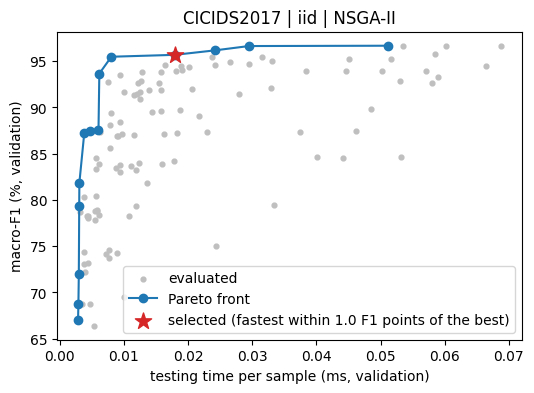

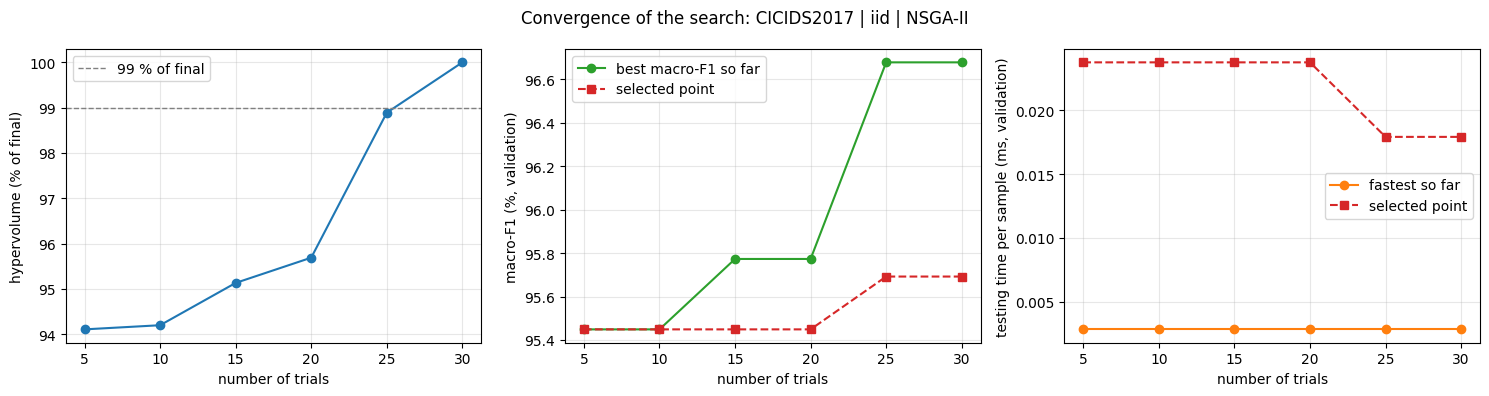

In [ ]:
params_cic_iid = moo_tune(df, "CICIDS2017", partition_mode="iid")

### Train and test with the selected parameters

In [ ]:
results_cic_iid_moo = run_eflboost(
    df,
    dataset_name="CICIDS2017",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    **params_cic_iid,
)

Dataset: CICIDS2017 (26800, 78) | mode=iid | clients=10
Params : n_trees=30, max_depth=8, learning_rate=0.26975154833351134, n_bins=128, lam=3.063462210622083, tuned=moo
  Client 0: 2144 samples, classes={np.int64(0): 1449, np.int64(3): 232, np.int64(1): 174, np.int64(6): 179, np.int64(5): 99, np.int64(2): 9, np.int64(4): 2}
  Client 1: 2144 samples, classes={np.int64(1): 159, np.int64(0): 1456, np.int64(3): 236, np.int64(6): 191, np.int64(5): 90, np.int64(2): 8, np.int64(4): 4}
  Client 2: 2144 samples, classes={np.int64(0): 1432, np.int64(3): 247, np.int64(6): 176, np.int64(1): 173, np.int64(5): 108, np.int64(2): 7, np.int64(4): 1}
  Client 3: 2144 samples, classes={np.int64(0): 1496, np.int64(1): 143, np.int64(3): 246, np.int64(6): 157, np.int64(5): 90, np.int64(4): 4, np.int64(2): 8}
  Client 4: 2144 samples, classes={np.int64(0): 1482, np.int64(5): 80, np.int64(1): 139, np.int64(3): 263, np.int64(6): 172, np.int64(2): 6, np.int64(4): 2}
  Client 5: 2144 samples, classes={np.int64(

### NSGA-III search and comparison with NSGA-II

  trial 1/30: {'n_trees': 40, 'max_depth': 8, 'learning_rate': 0.26975154833351134, 'n_bins': 32, 'lam': 0.014936568554617643} -> F1-macro 95.43 %, 0.0307 ms / sample
  trial 2/30: {'n_trees': 90, 'max_depth': 6, 'learning_rate': 0.2552951604697377, 'n_bins': 64, 'lam': 0.04335281794951567} -> F1-macro 93.94 %, 0.0570 ms / sample
  trial 3/30: {'n_trees': 20, 'max_depth': 3, 'learning_rate': 0.10074238942079328, 'n_bins': 32, 'lam': 0.6847920095574779} -> F1-macro 73.73 %, 0.0075 ms / sample
  trial 4/30: {'n_trees': 20, 'max_depth': 4, 'learning_rate': 0.11623364244752171, 'n_bins': 64, 'lam': 0.34890188454913873} -> F1-macro 86.87 %, 0.0090 ms / sample
  trial 5/30: {'n_trees': 60, 'max_depth': 2, 'learning_rate': 0.2025418890664837, 'n_bins': 128, 'lam': 7.886714129990489} -> F1-macro 89.72 %, 0.0189 ms / sample
  trial 6/30: {'n_trees': 90, 'max_depth': 4, 'learning_rate': 0.06260977143530197, 'n_bins': 32, 'lam': 0.3058656666978526} -> F1-macro 94.51 %, 0.0667 ms / sample
  trial 

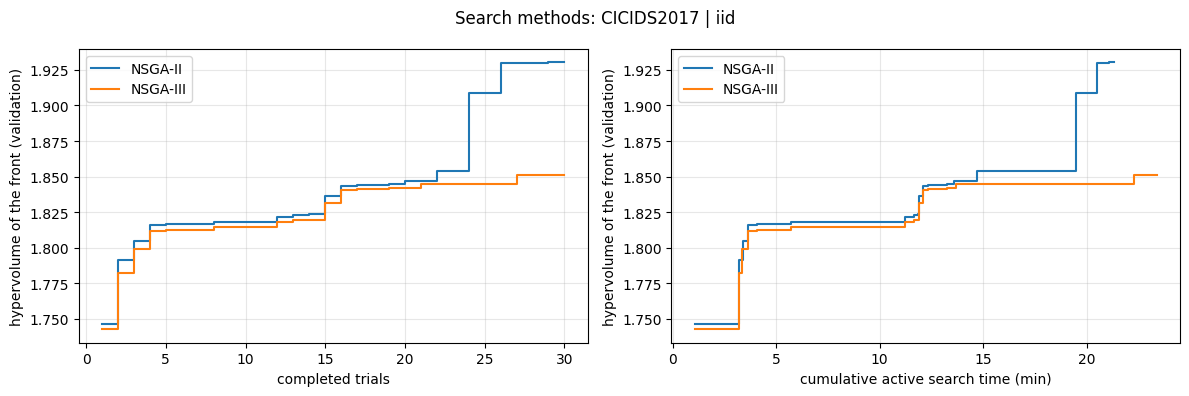

In [ ]:
params_cic_iid_nsga3 = moo_tune(df, "CICIDS2017", partition_mode="iid", algorithm="nsga3", plot=False)
compare_cic_iid = compare_searches("CICIDS2017", "iid")

### Train and test with the setting NSGA-III selected

In [18]:
results_cic_iid_nsga3 = run_eflboost(
    df,
    dataset_name="CICIDS2017",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    **params_cic_iid_nsga3,
)

Dataset: CICIDS2017 (26800, 78) | mode=iid | clients=10
Params : n_trees=30, max_depth=8, learning_rate=0.26975154833351134, n_bins=32, lam=0.014936568554617643, tuned=moo_nsga3
  Client 0: 2144 samples, classes={np.int64(0): 1449, np.int64(3): 232, np.int64(1): 174, np.int64(6): 179, np.int64(5): 99, np.int64(2): 9, np.int64(4): 2}
  Client 1: 2144 samples, classes={np.int64(1): 159, np.int64(0): 1456, np.int64(3): 236, np.int64(6): 191, np.int64(5): 90, np.int64(2): 8, np.int64(4): 4}
  Client 2: 2144 samples, classes={np.int64(0): 1432, np.int64(3): 247, np.int64(6): 176, np.int64(1): 173, np.int64(5): 108, np.int64(2): 7, np.int64(4): 1}
  Client 3: 2144 samples, classes={np.int64(0): 1496, np.int64(1): 143, np.int64(3): 246, np.int64(6): 157, np.int64(5): 90, np.int64(4): 4, np.int64(2): 8}
  Client 4: 2144 samples, classes={np.int64(0): 1482, np.int64(5): 80, np.int64(1): 139, np.int64(3): 263, np.int64(6): 172, np.int64(2): 6, np.int64(4): 2}
  Client 5: 2144 samples, classes={n

# Non-IID

In [19]:
results_cic_noniid = run_eflboost(
    df,
    dataset_name="CICIDS2017",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    n_trees=50,
    max_depth=6,
    n_bins=64,
    learning_rate=0.1,
)

Dataset: CICIDS2017 (26800, 78) | mode=dirichlet | clients=10
Params : n_trees=50, max_depth=6, learning_rate=0.1, n_bins=64, lam=0.1, tuned=False
  Client 0: 2023 samples, classes={np.int64(0): 113, np.int64(1): 1247, np.int64(3): 173, np.int64(4): 5, np.int64(5): 18, np.int64(6): 467}
  Client 1: 2202 samples, classes={np.int64(0): 1420, np.int64(1): 16, np.int64(2): 3, np.int64(3): 53, np.int64(4): 1, np.int64(5): 26, np.int64(6): 683}
  Client 2: 193 samples, classes={np.int64(0): 1, np.int64(1): 14, np.int64(2): 21, np.int64(3): 23, np.int64(4): 4, np.int64(5): 123, np.int64(6): 7}
  Client 3: 1263 samples, classes={np.int64(0): 757, np.int64(1): 19, np.int64(2): 20, np.int64(3): 444, np.int64(6): 23}
  Client 4: 9934 samples, classes={np.int64(0): 9513, np.int64(1): 166, np.int64(2): 7, np.int64(3): 4, np.int64(4): 1, np.int64(5): 26, np.int64(6): 217}
  Client 5: 1318 samples, classes={np.int64(0): 20, np.int64(1): 24, np.int64(2): 6, np.int64(3): 410, np.int64(4): 3, np.int64(5

### Multi-objective tuning (maximise macro-F1, minimise testing time)

  trial 1/30: {'n_trees': 40, 'max_depth': 8, 'learning_rate': 0.26975154833351134, 'n_bins': 32, 'lam': 0.014936568554617643} -> F1-macro 97.38 %, 0.0264 ms / sample
  trial 2/30: {'n_trees': 90, 'max_depth': 6, 'learning_rate': 0.2552951604697377, 'n_bins': 64, 'lam': 0.04335281794951567} -> F1-macro 95.83 %, 0.0700 ms / sample
  trial 3/30: {'n_trees': 20, 'max_depth': 3, 'learning_rate': 0.10074238942079328, 'n_bins': 32, 'lam': 0.6847920095574779} -> F1-macro 73.62 %, 0.0069 ms / sample
  trial 4/30: {'n_trees': 20, 'max_depth': 4, 'learning_rate': 0.11623364244752171, 'n_bins': 64, 'lam': 0.34890188454913873} -> F1-macro 84.81 %, 0.0081 ms / sample
  trial 5/30: {'n_trees': 60, 'max_depth': 2, 'learning_rate': 0.2025418890664837, 'n_bins': 128, 'lam': 7.886714129990489} -> F1-macro 89.89 %, 0.0155 ms / sample
  trial 6/30: {'n_trees': 90, 'max_depth': 4, 'learning_rate': 0.06260977143530197, 'n_bins': 32, 'lam': 0.3058656666978526} -> F1-macro 93.01 %, 0.0561 ms / sample
  trial 

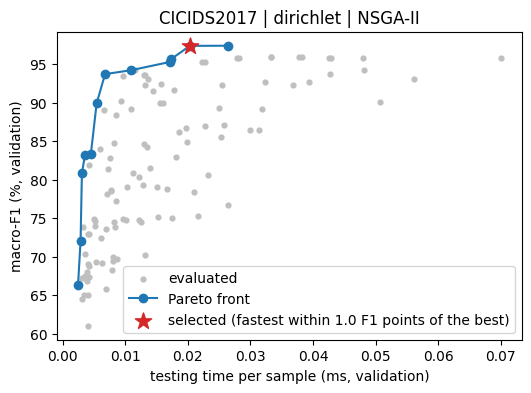

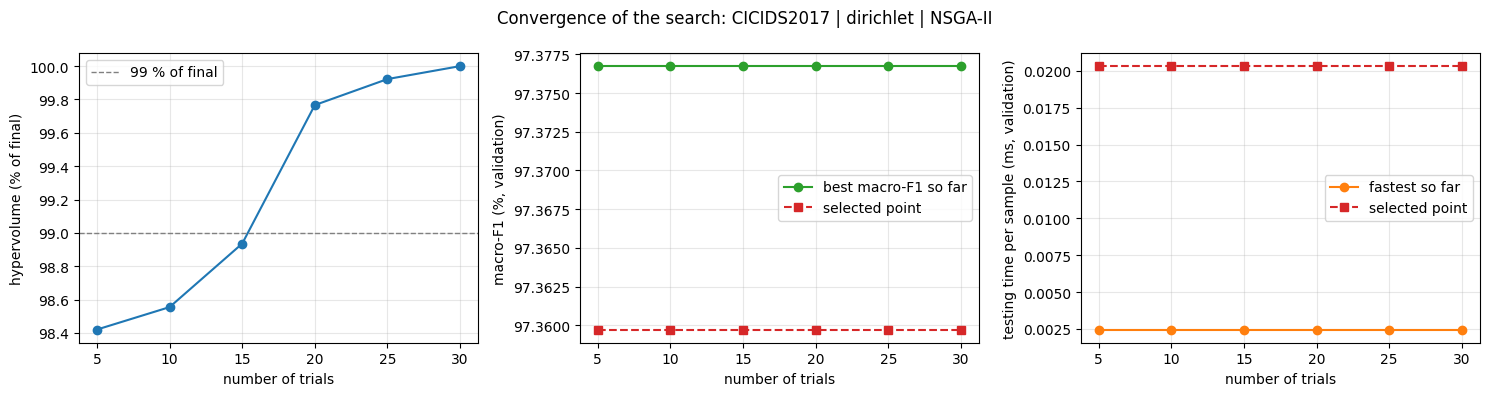

In [20]:
params_cic_noniid = moo_tune(df, "CICIDS2017", partition_mode="dirichlet", dirichlet_alpha=0.5)

### Train and test with the selected parameters

In [21]:
results_cic_noniid_moo = run_eflboost(
    df,
    dataset_name="CICIDS2017",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    **params_cic_noniid,
)

Dataset: CICIDS2017 (26800, 78) | mode=dirichlet | clients=10
Params : n_trees=30, max_depth=8, learning_rate=0.26975154833351134, n_bins=32, lam=0.014936568554617643, tuned=moo
  Client 0: 2023 samples, classes={np.int64(0): 113, np.int64(1): 1247, np.int64(3): 173, np.int64(4): 5, np.int64(5): 18, np.int64(6): 467}
  Client 1: 2202 samples, classes={np.int64(0): 1420, np.int64(1): 16, np.int64(2): 3, np.int64(3): 53, np.int64(4): 1, np.int64(5): 26, np.int64(6): 683}
  Client 2: 193 samples, classes={np.int64(0): 1, np.int64(1): 14, np.int64(2): 21, np.int64(3): 23, np.int64(4): 4, np.int64(5): 123, np.int64(6): 7}
  Client 3: 1263 samples, classes={np.int64(0): 757, np.int64(1): 19, np.int64(2): 20, np.int64(3): 444, np.int64(6): 23}
  Client 4: 9934 samples, classes={np.int64(0): 9513, np.int64(1): 166, np.int64(2): 7, np.int64(3): 4, np.int64(4): 1, np.int64(5): 26, np.int64(6): 217}
  Client 5: 1318 samples, classes={np.int64(0): 20, np.int64(1): 24, np.int64(2): 6, np.int64(3): 

### NSGA-III search and comparison with NSGA-II

  trial 1/30: {'n_trees': 40, 'max_depth': 8, 'learning_rate': 0.26975154833351134, 'n_bins': 32, 'lam': 0.014936568554617643} -> F1-macro 97.38 %, 0.0267 ms / sample
  trial 2/30: {'n_trees': 90, 'max_depth': 6, 'learning_rate': 0.2552951604697377, 'n_bins': 64, 'lam': 0.04335281794951567} -> F1-macro 95.83 %, 0.0480 ms / sample
  trial 3/30: {'n_trees': 20, 'max_depth': 3, 'learning_rate': 0.10074238942079328, 'n_bins': 32, 'lam': 0.6847920095574779} -> F1-macro 73.62 %, 0.0072 ms / sample
  trial 4/30: {'n_trees': 20, 'max_depth': 4, 'learning_rate': 0.11623364244752171, 'n_bins': 64, 'lam': 0.34890188454913873} -> F1-macro 84.81 %, 0.0083 ms / sample
  trial 5/30: {'n_trees': 60, 'max_depth': 2, 'learning_rate': 0.2025418890664837, 'n_bins': 128, 'lam': 7.886714129990489} -> F1-macro 89.89 %, 0.0158 ms / sample
  trial 6/30: {'n_trees': 90, 'max_depth': 4, 'learning_rate': 0.06260977143530197, 'n_bins': 32, 'lam': 0.3058656666978526} -> F1-macro 93.01 %, 0.0386 ms / sample
  trial 

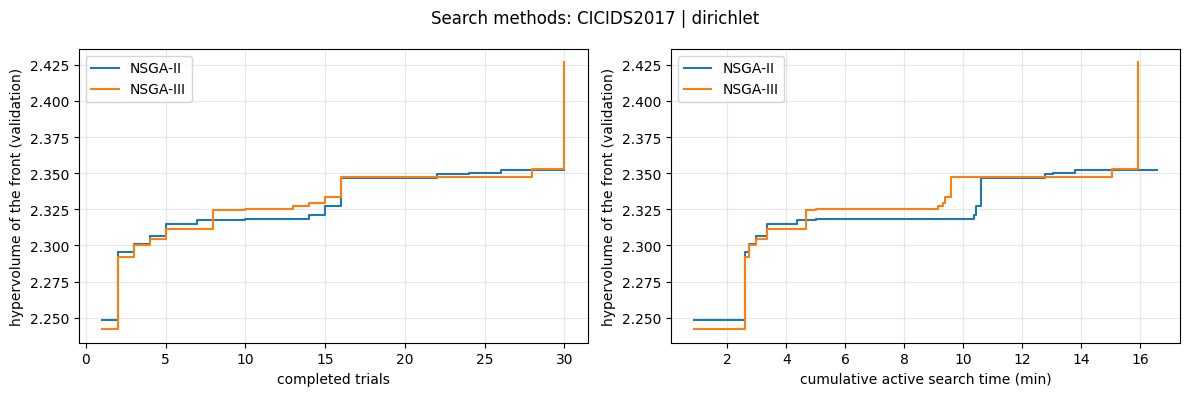

In [22]:
params_cic_noniid_nsga3 = moo_tune(df, "CICIDS2017", partition_mode="dirichlet", dirichlet_alpha=0.5, algorithm="nsga3", plot=False)
compare_cic_noniid = compare_searches("CICIDS2017", "dirichlet")

### Train and test with the setting NSGA-III selected

In [23]:
results_cic_noniid_nsga3 = run_eflboost(
    df,
    dataset_name="CICIDS2017",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    **params_cic_noniid_nsga3,
)

Dataset: CICIDS2017 (26800, 78) | mode=dirichlet | clients=10
Params : n_trees=50, max_depth=6, learning_rate=0.2552951604697377, n_bins=32, lam=0.34890188454913873, tuned=moo_nsga3
  Client 0: 2023 samples, classes={np.int64(0): 113, np.int64(1): 1247, np.int64(3): 173, np.int64(4): 5, np.int64(5): 18, np.int64(6): 467}
  Client 1: 2202 samples, classes={np.int64(0): 1420, np.int64(1): 16, np.int64(2): 3, np.int64(3): 53, np.int64(4): 1, np.int64(5): 26, np.int64(6): 683}
  Client 2: 193 samples, classes={np.int64(0): 1, np.int64(1): 14, np.int64(2): 21, np.int64(3): 23, np.int64(4): 4, np.int64(5): 123, np.int64(6): 7}
  Client 3: 1263 samples, classes={np.int64(0): 757, np.int64(1): 19, np.int64(2): 20, np.int64(3): 444, np.int64(6): 23}
  Client 4: 9934 samples, classes={np.int64(0): 9513, np.int64(1): 166, np.int64(2): 7, np.int64(3): 4, np.int64(4): 1, np.int64(5): 26, np.int64(6): 217}
  Client 5: 1318 samples, classes={np.int64(0): 20, np.int64(1): 24, np.int64(2): 6, np.int64(

# 2. IoTID2020

In [13]:
df = pd.read_csv("IoT_Network_Intrusion_Dataset_0.1.csv")

In [14]:
df = df.dropna(subset=["Label"])
print(df.shape)
le = LabelEncoder()
df["Label"] = le.fit_transform(df["Label"])
print("Label mapping:", dict(zip(le.classes_, range(len(le.classes_)))))

Label mapping: {'DoS': 0, 'MITM ARP Spoofing': 1, 'Mirai': 2, 'Normal': 3, 'Scan': 4, nan: 5}


# IID

In [26]:
results_iot_iid = run_eflboost(
    df,
    dataset_name="IoTID2020",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    n_trees=50,
    max_depth=6,
    n_bins=64,
    learning_rate=0.1,
)

Dataset: IoTID2020 (62578, 82) | mode=iid | clients=10
Params : n_trees=50, max_depth=6, learning_rate=0.1, n_bins=64, lam=0.1, tuned=False
  Client 0: 5007 samples, classes={np.int64(4): 623, np.int64(2): 3290, np.int64(0): 483, np.int64(1): 315, np.int64(3): 296}
  Client 1: 5007 samples, classes={np.int64(2): 3340, np.int64(0): 470, np.int64(1): 257, np.int64(3): 305, np.int64(4): 635}
  Client 2: 5006 samples, classes={np.int64(2): 3311, np.int64(1): 270, np.int64(3): 345, np.int64(4): 595, np.int64(0): 485}
  Client 3: 5006 samples, classes={np.int64(2): 3257, np.int64(0): 508, np.int64(3): 332, np.int64(4): 618, np.int64(1): 291}
  Client 4: 5006 samples, classes={np.int64(2): 3346, np.int64(4): 599, np.int64(3): 305, np.int64(0): 463, np.int64(1): 293}
  Client 5: 5006 samples, classes={np.int64(2): 3364, np.int64(1): 274, np.int64(4): 578, np.int64(3): 306, np.int64(0): 484}
  Client 6: 5006 samples, classes={np.int64(2): 3355, np.int64(1): 258, np.int64(0): 459, np.int64(4): 5

### Multi-objective tuning (maximise macro-F1, minimise testing time)

  trial 1/30: {'n_trees': 40, 'max_depth': 8, 'learning_rate': 0.26975154833351134, 'n_bins': 32, 'lam': 0.014936568554617643} -> F1-macro 97.31 %, 0.0297 ms / sample
  trial 2/30: {'n_trees': 90, 'max_depth': 6, 'learning_rate': 0.2552951604697377, 'n_bins': 64, 'lam': 0.04335281794951567} -> F1-macro 97.66 %, 0.0512 ms / sample
  trial 3/30: {'n_trees': 20, 'max_depth': 3, 'learning_rate': 0.10074238942079328, 'n_bins': 32, 'lam': 0.6847920095574779} -> F1-macro 91.78 %, 0.0060 ms / sample
  trial 4/30: {'n_trees': 20, 'max_depth': 4, 'learning_rate': 0.11623364244752171, 'n_bins': 64, 'lam': 0.34890188454913873} -> F1-macro 93.68 %, 0.0085 ms / sample
  trial 5/30: {'n_trees': 60, 'max_depth': 2, 'learning_rate': 0.2025418890664837, 'n_bins': 128, 'lam': 7.886714129990489} -> F1-macro 93.75 %, 0.0209 ms / sample
  trial 6/30: {'n_trees': 90, 'max_depth': 4, 'learning_rate': 0.06260977143530197, 'n_bins': 32, 'lam': 0.3058656666978526} -> F1-macro 95.13 %, 0.0343 ms / sample
  trial 

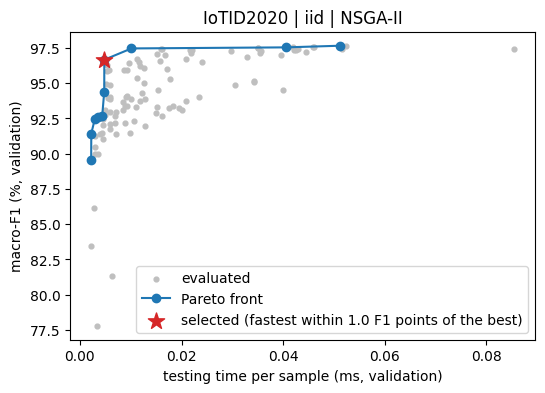

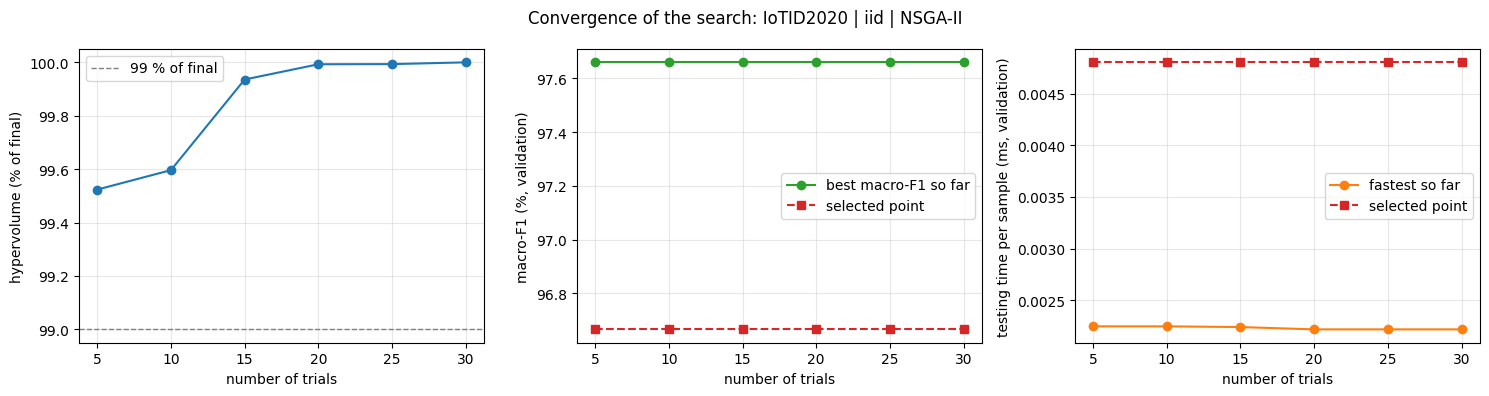

In [27]:
params_iot_iid = moo_tune(df, "IoTID2020", partition_mode="iid")

### Train and test with the selected parameters

In [28]:
results_iot_iid_moo = run_eflboost(
    df,
    dataset_name="IoTID2020",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    **params_iot_iid,
)

Dataset: IoTID2020 (62578, 82) | mode=iid | clients=10
Params : n_trees=10, max_depth=6, learning_rate=0.2552951604697377, n_bins=64, lam=0.04335281794951567, tuned=moo
  Client 0: 5007 samples, classes={np.int64(4): 623, np.int64(2): 3290, np.int64(0): 483, np.int64(1): 315, np.int64(3): 296}
  Client 1: 5007 samples, classes={np.int64(2): 3340, np.int64(0): 470, np.int64(1): 257, np.int64(3): 305, np.int64(4): 635}
  Client 2: 5006 samples, classes={np.int64(2): 3311, np.int64(1): 270, np.int64(3): 345, np.int64(4): 595, np.int64(0): 485}
  Client 3: 5006 samples, classes={np.int64(2): 3257, np.int64(0): 508, np.int64(3): 332, np.int64(4): 618, np.int64(1): 291}
  Client 4: 5006 samples, classes={np.int64(2): 3346, np.int64(4): 599, np.int64(3): 305, np.int64(0): 463, np.int64(1): 293}
  Client 5: 5006 samples, classes={np.int64(2): 3364, np.int64(1): 274, np.int64(4): 578, np.int64(3): 306, np.int64(0): 484}
  Client 6: 5006 samples, classes={np.int64(2): 3355, np.int64(1): 258, np.

### NSGA-III search and comparison with NSGA-II

In [15]:
params_iot_iid_nsga3 = moo_tune(df, "IoTID2020", partition_mode="iid", algorithm="nsga3", plot=False)
compare_iot_iid = compare_searches("IoTID2020", "iid")

ValueError: The least populated class in y has only 1 member, which is too few. The minimum number of groups for any class cannot be less than 2.

### Train and test with the setting NSGA-III selected

In [ ]:
results_iot_iid_nsga3 = run_eflboost(
    df,
    dataset_name="IoTID2020",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    **params_iot_iid_nsga3,
)

# Non-IID

In [31]:
results_iot_noniid = run_eflboost(
    df,
    dataset_name="IoTID2020",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    n_trees=50,
    max_depth=6,
    n_bins=64,
    learning_rate=0.1,
)

Dataset: IoTID2020 (62578, 82) | mode=dirichlet | clients=10
Params : n_trees=50, max_depth=6, learning_rate=0.1, n_bins=64, lam=0.1, tuned=False
  Client 0: 2052 samples, classes={np.int64(0): 53, np.int64(1): 818, np.int64(2): 644, np.int64(3): 6, np.int64(4): 531}
  Client 1: 13332 samples, classes={np.int64(0): 1549, np.int64(1): 128, np.int64(2): 11434, np.int64(3): 211, np.int64(4): 10}
  Client 2: 2937 samples, classes={np.int64(0): 149, np.int64(1): 47, np.int64(2): 1780, np.int64(3): 745, np.int64(4): 216}
  Client 3: 10645 samples, classes={np.int64(0): 31, np.int64(1): 6, np.int64(2): 9902, np.int64(3): 203, np.int64(4): 503}
  Client 4: 1744 samples, classes={np.int64(0): 314, np.int64(1): 30, np.int64(2): 209, np.int64(3): 111, np.int64(4): 1080}
  Client 5: 5947 samples, classes={np.int64(0): 237, np.int64(1): 179, np.int64(2): 5316, np.int64(3): 208, np.int64(4): 7}
  Client 6: 1806 samples, classes={np.int64(0): 104, np.int64(1): 118, np.int64(2): 58, np.int64(3): 63, n

### Multi-objective tuning (maximise macro-F1, minimise testing time)

  trial 1/30: {'n_trees': 40, 'max_depth': 8, 'learning_rate': 0.26975154833351134, 'n_bins': 32, 'lam': 0.014936568554617643} -> F1-macro 96.27 %, 0.0270 ms / sample
  trial 2/30: {'n_trees': 90, 'max_depth': 6, 'learning_rate': 0.2552951604697377, 'n_bins': 64, 'lam': 0.04335281794951567} -> F1-macro 97.84 %, 0.0671 ms / sample
  trial 3/30: {'n_trees': 20, 'max_depth': 3, 'learning_rate': 0.10074238942079328, 'n_bins': 32, 'lam': 0.6847920095574779} -> F1-macro 82.50 %, 0.0053 ms / sample
  trial 4/30: {'n_trees': 20, 'max_depth': 4, 'learning_rate': 0.11623364244752171, 'n_bins': 64, 'lam': 0.34890188454913873} -> F1-macro 92.50 %, 0.0064 ms / sample
  trial 5/30: {'n_trees': 60, 'max_depth': 2, 'learning_rate': 0.2025418890664837, 'n_bins': 128, 'lam': 7.886714129990489} -> F1-macro 93.83 %, 0.0120 ms / sample
  trial 6/30: {'n_trees': 90, 'max_depth': 4, 'learning_rate': 0.06260977143530197, 'n_bins': 32, 'lam': 0.3058656666978526} -> F1-macro 94.05 %, 0.0325 ms / sample
  trial 

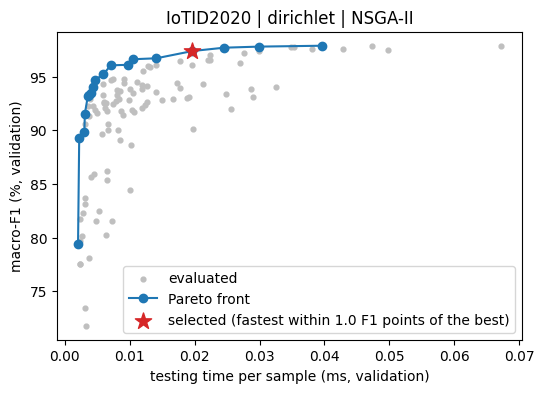

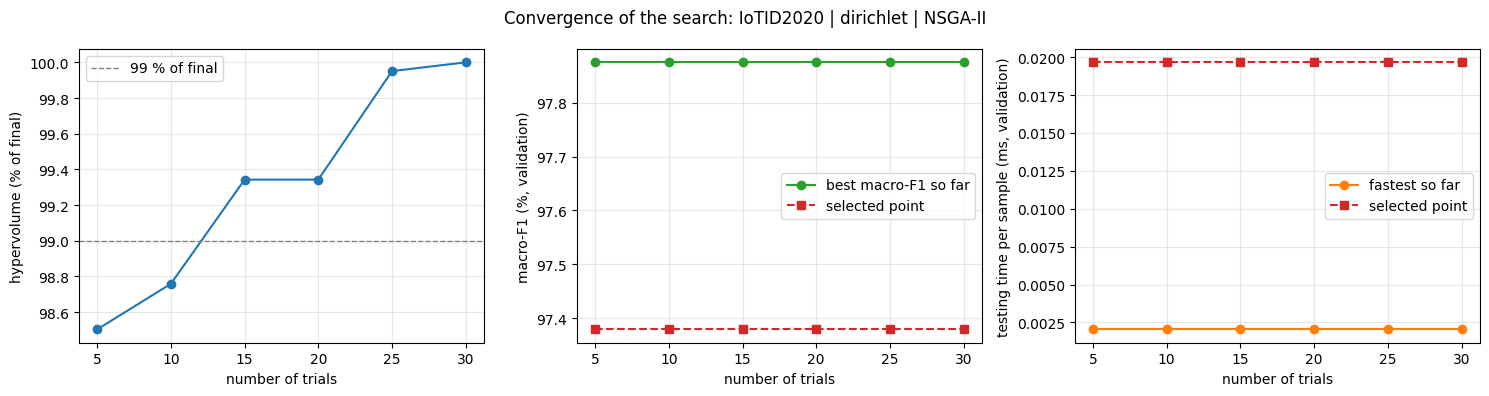

In [32]:
params_iot_noniid = moo_tune(df, "IoTID2020", partition_mode="dirichlet", dirichlet_alpha=0.5)

### Train and test with the selected parameters

In [ ]:
results_iot_noniid_moo = run_eflboost(
    df,
    dataset_name="IoTID2020",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    **params_iot_noniid,
)

### NSGA-III search and comparison with NSGA-II

In [ ]:
params_iot_noniid_nsga3 = moo_tune(df, "IoTID2020", partition_mode="dirichlet", dirichlet_alpha=0.5, algorithm="nsga3", plot=False)
compare_iot_noniid = compare_searches("IoTID2020", "dirichlet")

  trial 1/30: {'n_trees': 40, 'max_depth': 8, 'learning_rate': 0.26975154833351134, 'n_bins': 32, 'lam': 0.014936568554617643} -> F1-macro 96.27 %, 0.0270 ms / sample
  trial 2/30: {'n_trees': 90, 'max_depth': 6, 'learning_rate': 0.2552951604697377, 'n_bins': 64, 'lam': 0.04335281794951567} -> F1-macro 97.84 %, 0.0454 ms / sample
  trial 3/30: {'n_trees': 20, 'max_depth': 3, 'learning_rate': 0.10074238942079328, 'n_bins': 32, 'lam': 0.6847920095574779} -> F1-macro 82.50 %, 0.0054 ms / sample
  trial 4/30: {'n_trees': 20, 'max_depth': 4, 'learning_rate': 0.11623364244752171, 'n_bins': 64, 'lam': 0.34890188454913873} -> F1-macro 92.50 %, 0.0064 ms / sample
  trial 5/30: {'n_trees': 60, 'max_depth': 2, 'learning_rate': 0.2025418890664837, 'n_bins': 128, 'lam': 7.886714129990489} -> F1-macro 93.83 %, 0.0119 ms / sample
  trial 6/30: {'n_trees': 90, 'max_depth': 4, 'learning_rate': 0.06260977143530197, 'n_bins': 32, 'lam': 0.3058656666978526} -> F1-macro 94.05 %, 0.0329 ms / sample
  trial 

### Train and test with the setting NSGA-III selected

In [ ]:
results_iot_noniid_nsga3 = run_eflboost(
    df,
    dataset_name="IoTID2020",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    **params_iot_noniid_nsga3,
)

# 3. CICEVSE2024

In [ ]:
df = pd.read_csv("CICEVSE2024_12classes_sample.csv")

# IID

In [ ]:
results_evse_iid = run_eflboost(
    df,
    dataset_name="CICEVSE2024",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    n_trees=50,
    max_depth=6,
    n_bins=64,
    learning_rate=0.1,
)

### Multi-objective tuning (maximise macro-F1, minimise testing time)

In [ ]:
params_evse_iid = moo_tune(df, "CICEVSE2024", partition_mode="iid")

### Train and test with the selected parameters

In [ ]:
results_evse_iid_moo = run_eflboost(
    df,
    dataset_name="CICEVSE2024",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    **params_evse_iid,
)

### NSGA-III search and comparison with NSGA-II

In [ ]:
params_evse_iid_nsga3 = moo_tune(df, "CICEVSE2024", partition_mode="iid", algorithm="nsga3", plot=False)
compare_evse_iid = compare_searches("CICEVSE2024", "iid")

### Train and test with the setting NSGA-III selected

In [ ]:
results_evse_iid_nsga3 = run_eflboost(
    df,
    dataset_name="CICEVSE2024",
    label_col="Label",
    partition_mode="iid",
    n_clients=10,
    **params_evse_iid_nsga3,
)

# Non-IID

In [ ]:
results_evse_noniid = run_eflboost(
    df,
    dataset_name="CICEVSE2024",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    n_trees=50,
    max_depth=6,
    n_bins=64,
    learning_rate=0.1,
)

### Multi-objective tuning (maximise macro-F1, minimise testing time)

In [ ]:
params_evse_noniid = moo_tune(df, "CICEVSE2024", partition_mode="dirichlet", dirichlet_alpha=0.5)

### Train and test with the selected parameters

In [ ]:
results_evse_noniid_moo = run_eflboost(
    df,
    dataset_name="CICEVSE2024",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    **params_evse_noniid,
)

### NSGA-III search and comparison with NSGA-II

In [ ]:
params_evse_noniid_nsga3 = moo_tune(df, "CICEVSE2024", partition_mode="dirichlet", dirichlet_alpha=0.5, algorithm="nsga3", plot=False)
compare_evse_noniid = compare_searches("CICEVSE2024", "dirichlet")

### Train and test with the setting NSGA-III selected

In [ ]:
results_evse_noniid_nsga3 = run_eflboost(
    df,
    dataset_name="CICEVSE2024",
    label_col="Label",
    partition_mode="dirichlet",
    n_clients=10,
    dirichlet_alpha=0.5,
    **params_evse_noniid_nsga3,
)

# Summary of all runs

In [ ]:
summary = pd.DataFrame(ALL_RESULTS)
summary["utility"] = [float(utility(r.f1_macro, r.test_time_per_sample_ms, r.model_size_mb,
                                    UTILITY_REFS[(r.dataset, r.partition)]))
                      if (r.dataset, r.partition) in UTILITY_REFS else np.nan for r in summary.itertuples()]
summary.to_csv("eflboost_results.csv", index=False)
params_cols = ["n_boosting_rounds", "max_depth", "learning_rate", "n_bins", "lam"]
search_cols = ["algorithm", "max_trials", "trials_to_99pct_hv", "search_time_min"]

if MOO_FRONTS:
    validation = search_summary()
    validation.to_csv("eflboost_validation_results.csv", index=False)
    print("Validation results (selected setting of each search, validation split):")
    display(validation.round(4))

test_cols = ["dataset", "partition", "tuned", *params_cols, "accuracy", "f1_macro", "f1_weighted", "utility",
             "train_time_s", "test_time_total_s", "test_time_per_sample_ms", "model_size_mb", "n_trees", "n_nodes",
             "n_comm_rounds", "total_comm_mb", *search_cols]
print("Test results (every run, held-out test set):")
display(summary.reindex(columns=test_cols).round(4))

tuned_runs = summary[summary["val_f1_macro"].notna()] if "val_f1_macro" in summary else summary.iloc[0:0]
if len(tuned_runs):
    pairs = [("f1_macro", "val_f1_macro"), ("accuracy", "val_accuracy"), ("f1_weighted", "val_f1_weighted"),
             ("utility", "val_utility"), ("test_time_per_sample_ms", "val_time_per_sample_ms"),
             ("model_size_mb", "val_model_size_mb"), ("n_nodes", "val_n_nodes")]
    side = tuned_runs[["dataset", "partition", *search_cols, *params_cols]].copy()
    for test_c, val_c in pairs:
        name = test_c.replace("test_", "")
        side[f"{name} (val)"] = tuned_runs[val_c]
        side[f"{name} (test)"] = tuned_runs[test_c]
    print("Validation vs test (tuned runs):")
    display(side.round(4))